# Results Evaluation Pipeline
This notebook provides a results plotting and evaluation pipeline. If using different proteins replace occurences of HRAS, P53 and PTEN where they appear.

In [22]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
import numpy as np

RESULTS_DIR = "Final_Results"
DATASETS = ["HRAS", "P53", "PTEN"]
DATASET_COLOURS = {"HRAS": "blue", "P53": "orange", "PTEN": "green"}

# Add to encoders and regressors if utilising different or fewer models
ENCODERS = {
    "onehot": "One-hot", "bohn": "BOHN",
    "esm1_t6_43M_UR50S": "ESM-1 43M", "esm1_t12_85M_UR50S": "ESM-1 85M",
    "esm1_t34_670M_UR50S": "ESM-1 670M UR50S", "esm1_t34_670M_UR50D": "ESM-1 670M UR50D",
    "esm1_t34_670M_UR100": "ESM-1 670M UR100", "esm1b_t33_650M_UR50S": "ESM-1b 650M",
    "esm1v_t33_650M_UR90S_1": "ESM-1v 650M (1)", "esm1v_t33_650M_UR90S_2": "ESM-1v 650M (2)",
    "esm1v_t33_650M_UR90S_3": "ESM-1v 650M (3)", "esm1v_t33_650M_UR90S_4": "ESM-1v 650M (4)",
    "esm1v_t33_650M_UR90S_5": "ESM-1v 650M (5)", "esm2_t6_8M_UR50D": "ESM-2 8M",
    "esm2_t12_35M_UR50D": "ESM-2 35M", "esm2_t30_150M_UR50D": "ESM-2 150M",
    "esm2_t33_650M_UR50D": "ESM-2 650M", "esm2_t36_3B_UR50D": "ESM-2 3B",
    "esm2_t48_15B_UR50D": "ESM-2 15B", "esmc_300m": "ESM-C 300M",
    "esmc_600m": "ESM-C 600M", "esm3-open": "ESM-3 1.4B",
    "prot_bert": "ProtBERT 420M", "prot_t5_xl_half_uniref50-enc": "ProtT5 3B",
}

REGRESSORS = {
    "GaussianProcessRegressor": "GPR", "SVR": "SVR", "KernelRidge": "KRR",
    "LinearRegression": "Linear", "Lasso": "Lasso", "ElasticNet": "ElasticNet",
    "SGDRegressor": "SGD", "PLSRegressor": "PLS", "KNeighborsRegressor": "KNN",
    "DecisionTreeRegressor": "Decision Tree", "RandomForestRegressor": "Random Forest",
    "ExtraTreesRegressor": "Extra Trees", "AdaBoostRegressor": "AdaBoost",
    "GradientBoostingRegressor": "GB",
}

In [23]:
def plotResults(dataset, save=False):
    df = pd.read_csv(f"{RESULTS_DIR}/{dataset}_results.csv")
    df["encoder"] = df["encoder"].str.strip()
    df["regressor"] = df["regressor"].str.strip()

    # Naive baseline uses no encoder/regressor, so it sits outside the grid
    naive = df.loc[df["encoder"] == "Naïve", "mean_r2"].iloc[0]
    df = df[df["encoder"] != "Naïve"]

    # Encoders are ordered by family
    enc = [e for e in ENCODERS if e in set(df["encoder"])]

    # Regressors ordered by average performance, descending
    reg = df.groupby("regressor")["mean_r2"].mean().sort_values(ascending=False).index.tolist()
    grid = (df.pivot_table(index="encoder", columns="regressor", values="mean_r2").reindex(index=enc, columns=reg))

    # Colour centred on the naive baseline, floored at zero so a large negative doesn't flatten the scale
    norm = TwoSlopeNorm(vmin=0.0, vcenter=naive, vmax=0.80)
    labels = grid.map(lambda v: "" if pd.isna(v) else f"{v:.3f}")

    # NOTE: The following conditional is an artefact left over from the initial project, as HRAS had a wider results span,
    # though could still be used in exceptional cases where one protein is of more interest with relation to a specific set of methods
    if dataset == "HRAS":
        fig, ax = plt.subplots(figsize=(len(reg) * 0.8, len(enc) * 0.5))
    else:
        fig, ax = plt.subplots(figsize=(len(reg) * 0.85 + 2.0, len(enc) * 0.42 + 1.5))
    sns.heatmap(
        grid.clip(lower=0.0), annot=labels, fmt="", annot_kws={"size": 7},
        cmap="RdBu", norm=norm,
        linewidths=0.5, linecolor="white",
        cbar_kws={"label": "Mean R²", "shrink": 0.5},
        ax=ax,
    )

    ax.set_title(f"{dataset} - Mean R² by Encoder-Regressor Pairs\n"
                 f"(Colour Centred on Naïve Baseline, R² = {naive:.3f})", fontsize=11)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels([REGRESSORS.get(r, r) for r in reg], rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels([ENCODERS[e] for e in enc], rotation=0, fontsize=8)
    plt.tight_layout()
    if save:
        plt.savefig(f"figures/{dataset}_heatmap.png", dpi=300, bbox_inches="tight")
    plt.show()

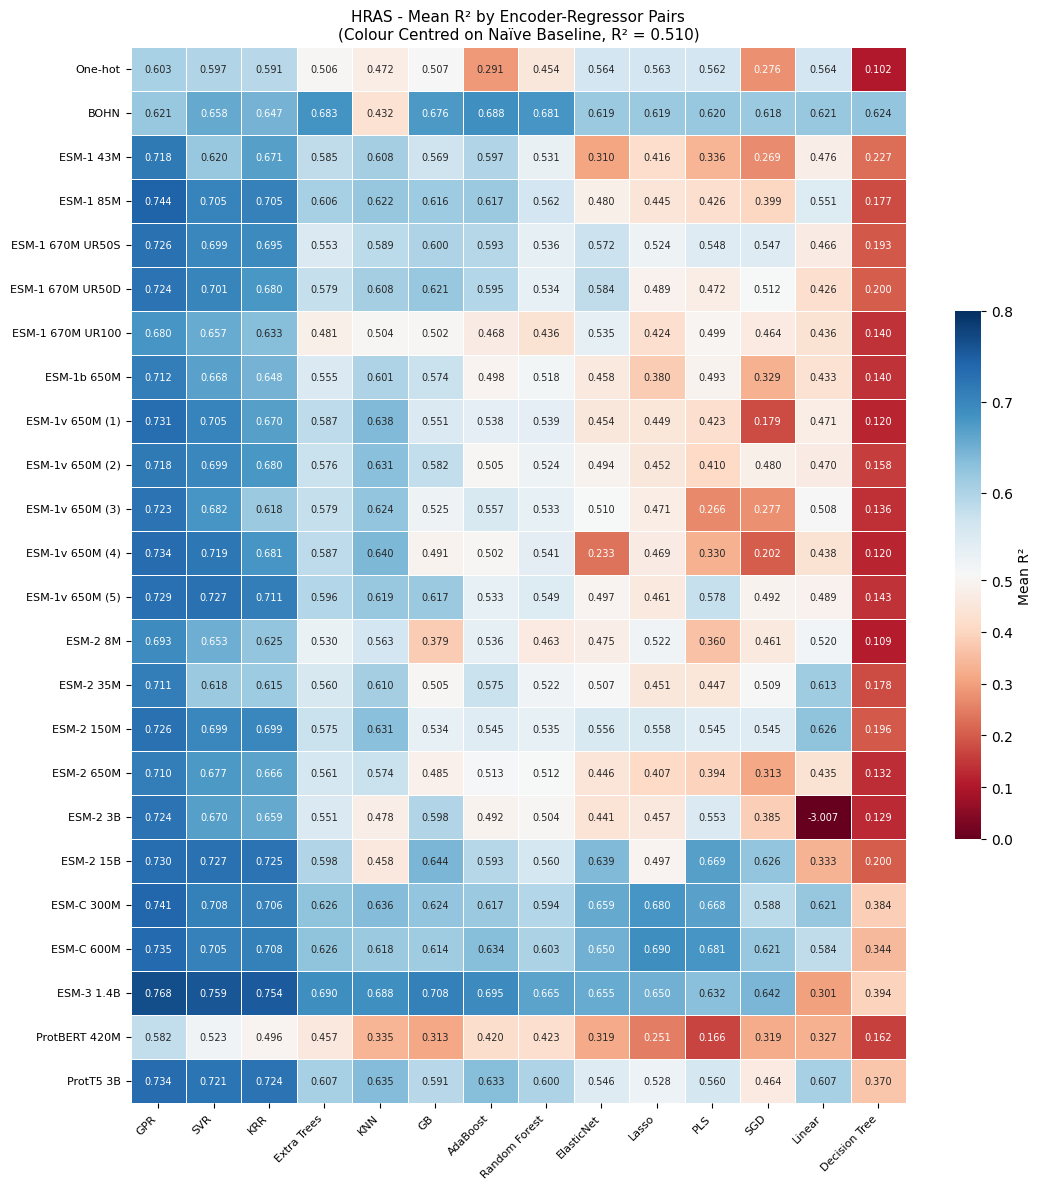

In [24]:
plotResults("HRAS")

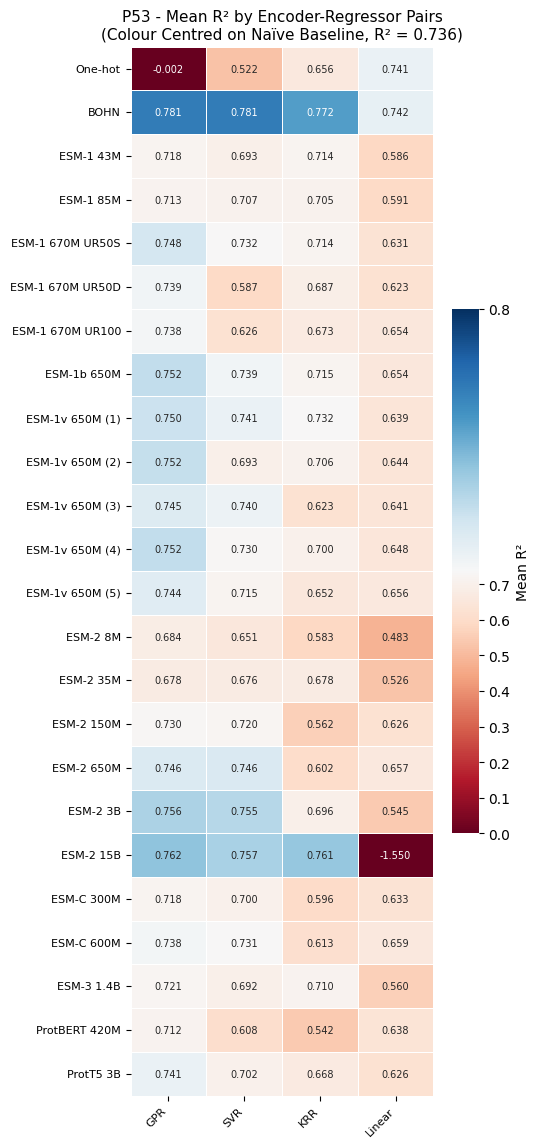

In [25]:
plotResults("P53")

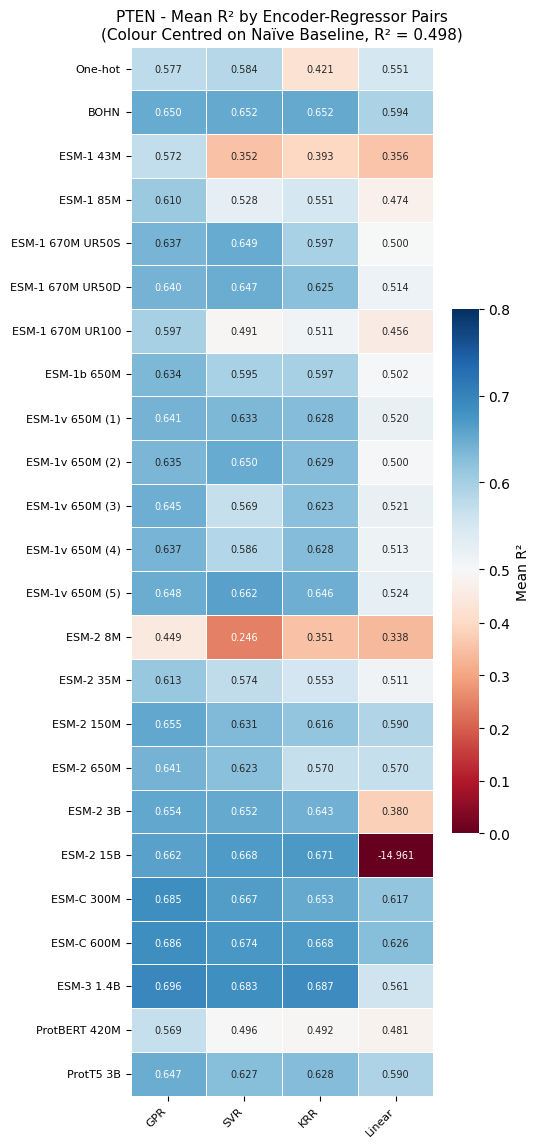

In [26]:
plotResults("PTEN")

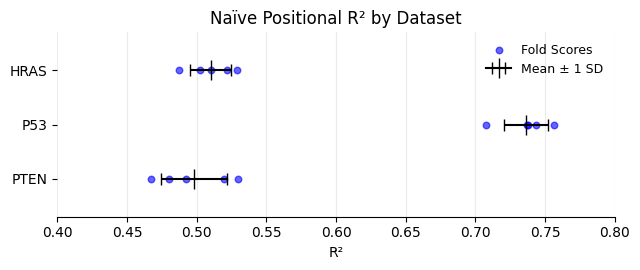

In [27]:
# Pulling the naive baseline row out of each results file
rows = []
for dataset in DATASETS:
    df = pd.read_csv(f"{RESULTS_DIR}/{dataset}_results.csv")
    naive = df[df["encoder"] == "Naïve"].iloc[0]
    rows.append({
        "dataset": dataset,
        "mean_r2": naive["mean_r2"],
        "std_r2": naive["std_r2"],
        "folds_r2": ast.literal_eval(naive["folds_r2"]),
    })

naive_df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 2.8))

for y, row in enumerate(naive_df.itertuples()):
    # Plotting fold level scores partly transparent so overlapping folds visible
    ax.scatter(row.folds_r2, [y] * len(row.folds_r2), color="blue", s=22, alpha=0.6, label="Fold Scores" if y == 0 else None)
    
    # Mean, with bar spanning one standard deviation either side
    ax.errorbar(row.mean_r2, y, xerr=row.std_r2, color="black", marker="|", markersize=14, capsize=4, label="Mean ± 1 SD" if y == 0 else None)

ax.set_yticks(range(len(naive_df)), naive_df["dataset"])
ax.invert_yaxis()
ax.margins(y=0.35)
ax.set_xlim(0.4, 0.8)
ax.set_xlabel("R²")
ax.set_title("Naïve Positional R² by Dataset")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="upper right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

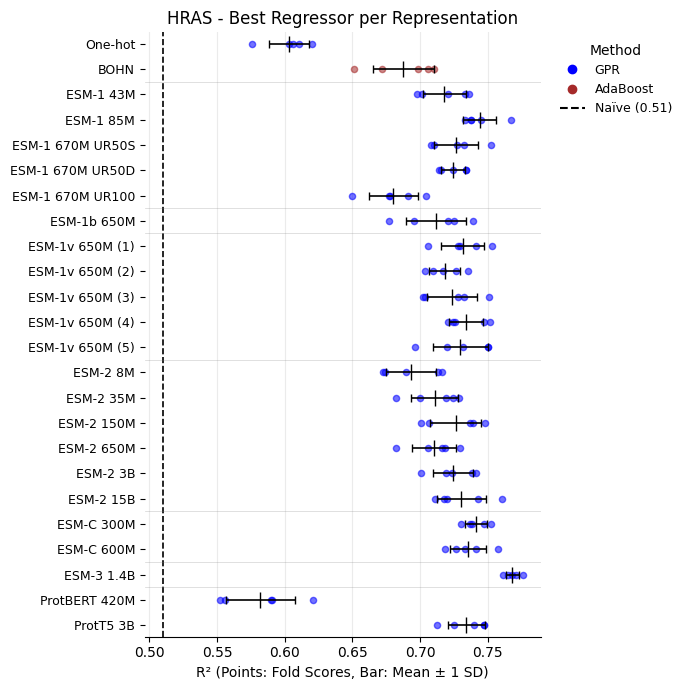

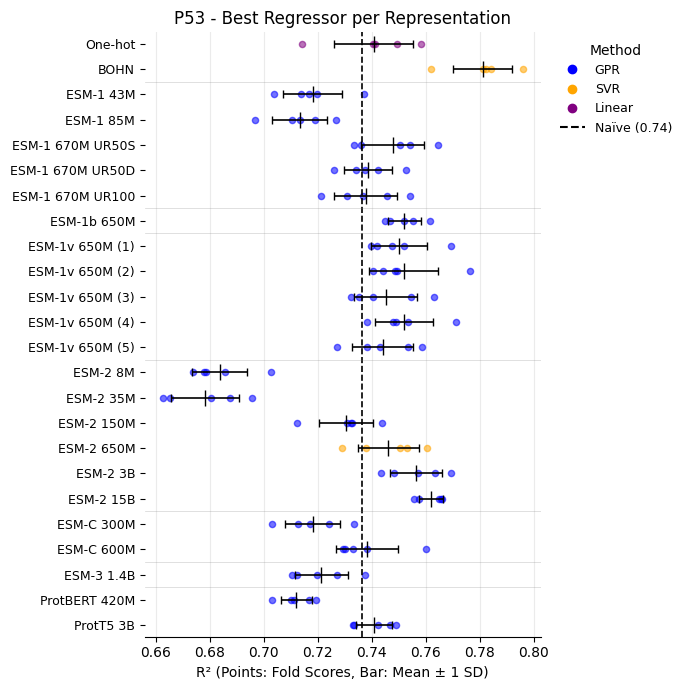

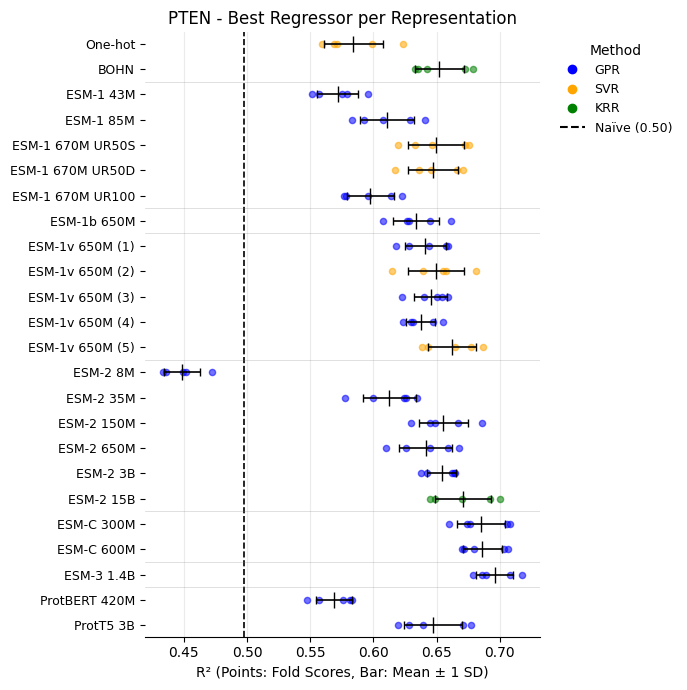

In [28]:
# Family boundaries/breaks
BREAKS = [2, 7, 8, 13, 19, 21, 22]

# Regressor colours
REGRESSOR_COLOURS = {
    "GaussianProcessRegressor": "blue", "SVR": "orange",
    "KernelRidge": "green", "LinearRegression": "purple",
    "AdaBoostRegressor": "brown",
}

# Labels
REGRESSOR_LABELS = {
    "GaussianProcessRegressor": "GPR", "SVR": "SVR", "KernelRidge": "KRR",
    "LinearRegression": "Linear", "AdaBoostRegressor": "AdaBoost",
}

# Defining function to plot top scoring regressor fold scores alongside mean and standard deviation per protein representation
def plotRepresentations(dataset):
    df = pd.read_csv(f"{RESULTS_DIR}/{dataset}_results.csv") # Reading results
    naive = df.loc[df["encoder"] == "Naïve", "mean_r2"].iloc[0] # Naive score
    df = df[df["encoder"] != "Naïve"] # Non-naive results data

    # Best regressor per representation (on average)
    best = df.loc[df.groupby("encoder")["mean_r2"].idxmax()].set_index("encoder")
    order = list(ENCODERS.keys())
    rows = best.reindex(order)

    fig, ax = plt.subplots(figsize=(7, 7))

    used = []
    for y, (encoder, row) in enumerate(rows.iterrows()):
        if pd.isna(row["mean_r2"]):
            continue
        colour = REGRESSOR_COLOURS[row["regressor"]]
        folds = ast.literal_eval(row["folds_r2"])
        ax.scatter(folds, [y] * len(folds), color=colour, s=20, alpha=0.55)
        ax.errorbar(row["mean_r2"], y, xerr=row["std_r2"], color="black", marker="|", markersize=11, capsize=3, linewidth=1.2)
        used.append(row["regressor"])

    ax.axvline(naive, color="black", linestyle="--", linewidth=1.2)

    for b in BREAKS:
        ax.axhline(b - 0.5, color="grey", linewidth=0.5, alpha=0.35)

    ax.set_yticks(range(len(order)), [ENCODERS[e] for e in order], fontsize=9)
    ax.invert_yaxis()
    ax.margins(y=0.02)
    ax.set_xlabel("R² (Points: Fold Scores, Bar: Mean ± 1 SD)")
    ax.set_title(f"{dataset} - Best Regressor per Representation")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

    # Plotting legend outside axes so it doesn't sit over information
    handles = [plt.Line2D([], [], color=REGRESSOR_COLOURS[r], marker="o", linestyle="", label=REGRESSOR_LABELS[r]) for r in REGRESSOR_COLOURS if r in used]
    handles.append(plt.Line2D([], [], color="black", linestyle="--", label=f"Naïve ({naive:.2f})"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9, title = "Method")
    plt.tight_layout()
    plt.show()

for dataset in ["HRAS", "P53", "PTEN"]:
    plotRepresentations(dataset)